Na programação orientada a objectos, o termo cliente refere-se a um programa que utiliza uma classe, ou instâncias de uma classe. Uma classe oferece os serviços de cliente através dos quais o cliente pode aceder aos objectos criados com base na classe:
- A utilização de uma classe e/ou objectos é tão simples quanto possível do ponto de vista do cliente
- A integridade de qualquer objecto é preservada a todo o momento

<br>

A integridade de um objecto significa que o estado de um objecto permanece sempre aceitável.

Na prática, isto significa que os valores dos atributos do objecto são sempre aceitáveis. Por exemplo, um objecto que representa uma data nunca deve ter 13 como valor do mês, um objecto que modela um estudante nunca deve ter um número negativo como o valor dos créditos de estudo alcançados, e assim por diante.

<br>
<br>
Por exemplo:

In [1]:
class Student:
    def __init__(self, name: str, student_number: str):
        self.name = name
        self.student_number = student_number
        self.study_credits = 0

    def add_credits(self, study_credits):
        if study_credits > 0:
            self.study_credits += study_credits

A classe  **Student** oferece aos seus clientes o método add_credits, que permite ao cliente adicionar um número especificado de créditos ao total do estudante. O método garante o valor passado, uma vez que o argumento está acima de zero.
<br>
O seguinte código adiciona créditos de estudo em três chamadas:

In [2]:
joao = Student("joao neves", "12345")
joao.add_credits(5)
joao.add_credits(5)
joao.add_credits(10)
print("Study credits:", joao.study_credits)

Study credits: 20


Todavia, ainda é possível aceder directamente ao atributo study_credits. Isto pode resultar num estado erróneo em que a integridade do objecto se perde:

In [3]:
joao = Student("joao neves", "12345")
joao.study_credits = -100
print("Study credits:", joao.study_credits)

Study credits: -100


Não faz sentido!

## Encapsulamento

Uma característica comum em linguagens de programação orientadas a objectos é que as classes podem normalmente esconder os seus atributos de qualquer potencial cliente.
<br>
Os atributos ocultos são normalmente chamados privados (não-publicos). Em Python esta privacidade é conseguida adicionando dois underscores **__** ao início do nome do atributo.


<br>
Por exemplo:


In [4]:
class CreditCard:
    # the attribute number is private, while the attribute name is accessible
    def __init__(self, number: str, name: str):
        self.__number = number
        self.name = name

Um atributo privado não é directamente visível para o cliente.
- Tentar aceder a esse causa um erro.

<br>

No exemplo o atributo *name* pode ser facilmente acedido e alterado:

In [5]:
card = CreditCard("123456","joão neves")
print(card.name)
card.name = "joao branco"
print(card.name)

joão neves
joao branco


Mas se tentamos imprimir o número do cartão, no entanto, causa e erro:

In [6]:
print(card.__number)

AttributeError: 'CreditCard' object has no attribute '__number'


<br>
<br>

A ocultação de atributos dos clientes é chamado **encapsulamento**. Como o nome implica, o atributo é "encapsulado numa cápsula".

- É oferecida ao cliente uma interface adequada para aceder e processar os dados armazenados no objecto.
- O objetivo é implementar classes de forma que as instâncias dessas não possam causar nenhum acesso não autorizado ou alteração no conteúdo original da classe.
- Uma classe não precisa saber nada sobre os algoritmos subjacentes de outra classe. No entanto, os dois ainda podem se comunicar.

Vantagens do encapsulamento:

- As classes tornam o código fácil de alterar e manter.

- As propriedades a serem ocultadas podem ser especificadas facilmente.

- Decidimos quais classes ou funções externas podem aceder as propriedades da classe.


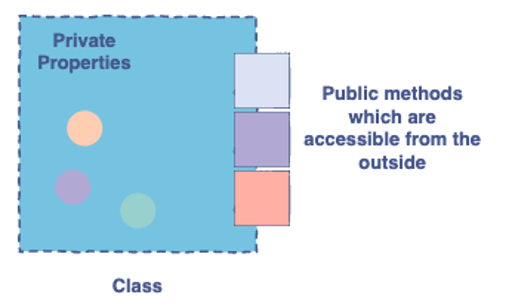


Vamos acrescentar outro atributo encapsulado:

O saldo no cartão de crédito. Desta vez vamos também adicionar métodos publicamente visíveis que permitem ao cliente aceder e alterar o saldo:

In [7]:
class CreditCard:
    def __init__(self, number: str, name: str, balance: float):
        self.__number = number
        self.name = name
        self.__balance = balance

    def deposit_money(self, amount: float):
        if amount > 0:
            self.__balance += amount

    def withdraw_money(self, amount: float):
        if amount > 0 and amount <= self.__balance:
            self.__balance -= amount

    def retrieve_balance(self):
        return self.__balance

In [8]:
card = CreditCard("123456", "joao neves", 5000)
print(card.retrieve_balance())
card.deposit_money(100)
print(card.retrieve_balance())
card.withdraw_money(500)
print(card.retrieve_balance())
# The following will not work because the balance is not sufficient
card.withdraw_money(10000)
print(card.retrieve_balance())

5000
5100
4600
4600


O saldo não pode ser alterado directamente porque o atributo é privado, mas incluímos os métodos:
*deposit_money* e *withdraw_money* para alterar o valor. O método *retrieve_balance* retorna o valor armazenado em saldo.

<br>

Os métodos incluem algumas verificações rudimentares para reter a integridade do objecto: por exemplo, o cartão não pode ser extraído a descoberto.

### Getters e setters

Na programação orientada a objectos, os métodos que são dedicados ao acesso e mudança de atributos são normalmente chamados *getters* e *setters*

- Um método getter permite ler o valor de uma propriedade.
- Um método setter permite modificar o valor de uma propriedade.

In [9]:
class User:
    def __init__(self, username=None):
        self.__username = username


    def set_username(self, x):
        self.__username = x

    def get_username(self):
        return self.__username

In [10]:
steve = User('steve1')
print('Before setting: ', steve.get_username())
steve.set_username('steve2')
print('After setting: ', steve.get_username())

Before setting:  steve1
After setting:  steve2


### Properties

Não todos os programadores python usam os termos getter e setter, mas o conceito de *property* que é uma terminologia e pratica de programação orientada a objectos geralmente aceite; uma forma mais *pythonic* de aceder aos atributos; permite aceder um metodo como se fosse um atributo
<br>

Por exemplo, um classe Wallet com um único atributo privado, money. Podemos adicionar os métodos *getter* e *setter* para aceder ao atributo privado utilizando o **@property decorator**

In [11]:
class Wallet:
    def __init__(self):
        self.__money = 0

    # A getter method
    @property
    def money(self):
        return self.__money

    # A setter method
    @money.setter
    def money(self, money):
        if money >= 0:
            self.__money = money
        else:
            raise ValueError("The amount must not be below zero")

In [12]:
wallet = Wallet()
print(wallet.money)

wallet.money = 50
print(wallet.money)

0
50


In [13]:
wallet.money = -30
print(wallet.money)

ValueError: The amount must not be below zero



- O método getter, isto é, o *@property decorator*, deve ser introduzido antes do método setter.
- O @property decorator define o nome do atributo.
- O método setter, adicionado com .setter, deve ter o mesmo nome que o método equivalente que @property decora.
- Aceita como argumento o valor que o utilizador define para a propriedade.
- É necessário adicionar um @{methodname}.setter decorator imediatamente antes da definição do método.



O exemplo seguinte tem uma classe com dois atributos privados, juntamente com getters e setters para ambos.

In [14]:
class Player:
    def __init__(self, name: str, player_number: int):
        self.__name = name
        self.__player_number = player_number

    @property
    def name(self):
        return self.__name

    @name.setter
    def name(self, name: str):
        if name != "":
            self.__name = name
        else:
            raise ValueError("The name may not be an empty string")

    @property
    def player_number(self):
        return self.__player_number

    @player_number.setter
    def player_number(self, player_number: int):
        if player_number > 0:
            self.__player_number = player_number
        else:
            raise ValueError("The player number must be a positive integer")

In [16]:
player = Player("john snow", 10)
print(player.name)
print(player.player_number)

player.name = "john dragon"
player.player_number = 11
print(player.name)
print(player.player_number)

john snow
10
john dragon
11



<br>
<br>


Vamos considerar a uma classe que modela um simples diário.
<br>
Todos os atributos são privados, mas são tratados através de interfaces diferentes:


* o atributo owner do diario tem métodos getter e setter
* as entries do diario são processadas com métodos "tradicionais"

<br>

O encapsulamento também assegura que a implementação interna da classe pode ser alterada à vontade, desde que a interface pública se mantenha intacta. O client não tem de saber ou preocupar-se se a estrutura de dados interna é baseada em listas, dicionários, ou algo completamente diferente.

In [17]:
class Diary:
    def __init__(self, owner: str):
        self.__owner = owner
        self.__entries = []

    @property
    def owner(self):
        return self.__owner

    @owner.setter
    def owner(self, owner):
        if owner != "":
            self.__owner = owner
        else:
            raise ValueError("The owner may not be an empty string")

    def add_entry(self, entry: str):
        self.__entries.append(entry)

    def print_entries(self):
        print("A total of", len(self.__entries), "entries")
        for entry in self.__entries:
            print("- " + entry)

In [18]:
diary = Diary("john")
diary.add_entry("Today I run")
diary.add_entry("Today I learned object oriented programming")
diary.add_entry("Today I went to bed early")
diary.print_entries()

A total of 3 entries
- Today I run
- Today I learned object oriented programming
- Today I went to bed early
